# Entrega final · Analista de inversiones
Basado en el notebook anterior, con las métricas **requeridas en el reparto**. Usa `clean.investments` + `clean.funding_rounds` como fuente de respaldo cuando los marts de Cristina aún no están cargados.

**Importante:** no confunde que una celda termine sin error con que existan resultados. Si no hay participaciones, detiene la ejecución con un diagnóstico. No modifica la base.

**Definiciones:** activo = al menos una ronda entre 2011 y 2013; éxito V1 = IPO o adquisición después de primera participación hasta 2013; éxito V2 = ronda posterior de la empresa; benchmark por industria, etapa y cohorte; portafolio mínimo = 5 empresas (editable).


**Corrección de compatibilidad:** se detectan `company_id` y las claves disponibles en cada tabla. Los nombres de inversionistas son opcionales; se usa el ID cuando no hay dimensión con nombres. Si faltan datos imprescindibles, se muestra un error explícito.

## 1 · Conexión y revisión de fuentes

In [1]:
from pathlib import Path
import duckdb, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
MIN_PORTAFOLIO = 5
INICIO, CORTE = '2011-01-01', '2013-12-31'
RUTA_DB = ''  # Solo si la detección automática no encuentra tu base
candidatas = [Path(RUTA_DB)] if RUTA_DB else []
for x in [Path.cwd(), *Path.cwd().parents, Path.home()/'proyectofinal'/'proyecto_bi_codigo_ligero'/'proyecto_bi_crunchbase']:
    candidatas += [x/'build'/'crunchbase.duckdb', x/'crunchbase.duckdb']
DB = next((x for x in candidatas if x.is_file()), None)
if DB is None:
    raise FileNotFoundError('No se encontró build/crunchbase.duckdb. Escribí la ruta en RUTA_DB.')
con=duckdb.connect(str(DB),read_only=True)
print('BASE:',DB)
display(con.execute("SELECT table_schema,table_name FROM information_schema.tables WHERE table_schema IN ('clean','marts') ORDER BY 1,2").df())
def tiene(schema,table):
    return con.execute('SELECT COUNT(*) FROM information_schema.tables WHERE table_schema=? AND table_name=?',[schema,table]).fetchone()[0]>0
def cols(schema,table):
    return set(con.execute(f'SELECT * FROM {schema}.{table} LIMIT 0').df().columns)
def columna(schema,table,opciones,required=True):
    x=next((a for a in opciones if a in cols(schema,table)),None)
    if required and not x: raise ValueError(f'Falta columna en {schema}.{table}: {opciones}. Disponibles: {cols(schema,table)}')
    return x


BASE: C:\Users\Nany\proyectofinal\proyecto_bi_codigo_ligero\proyecto_bi_crunchbase\build\crunchbase.duckdb


,table_schema,table_name
0,clean,acquisitions
1,clean,bitacora_calidad
2,clean,cuarentena
3,clean,degrees
4,clean,eventos_empresa
5,clean,funding_rounds
6,clean,funds
7,clean,fx_implicito
8,clean,ids_empresa
9,clean,investments


if not (tiene('clean','investments') and tiene('clean','funding_rounds')):
    raise RuntimeError('Faltan clean.investments o clean.funding_rounds. Ejecutá el pipeline del proyecto.')
ic=cols('clean','investments'); rc=cols('clean','funding_rounds')
print('Inversiones:',con.execute('SELECT count(*) FROM clean.investments').fetchone()[0])
print('Rondas:',con.execute('SELECT count(*) FROM clean.funding_rounds').fetchone()[0])
i_id=columna('clean','investments',['investor_object_id','investor_id','inversionista_id'])
i_ronda=columna('clean','investments',['funding_round_id','ronda_id'])
r_id=columna('clean','funding_rounds',['funding_round_id','ronda_id'])
r_empresa=columna('clean','funding_rounds',['company_id','object_id','empresa_id'])
r_fecha=columna('clean','funding_rounds',['funded_at','fecha'])
participaciones=con.execute(f'''
SELECT DISTINCT i."{i_id}" AS inversionista_id, r."{r_id}" AS ronda_id,
       r."{r_empresa}" AS empresa_id, TRY_CAST(r."{r_fecha}" AS DATE) AS fecha
FROM clean.investments i
JOIN clean.funding_rounds r ON i."{i_ronda}"=r."{r_id}"
WHERE i."{i_id}" IS NOT NULL AND r."{r_empresa}" IS NOT NULL
AND TRY_CAST(r."{r_fecha}" AS DATE)<=DATE '2013-12-31'
''').df()
participaciones['fecha']=pd.to_datetime(participaciones.fecha)
print('Participaciones válidas:',len(participaciones))
if participaciones.empty:
    raise RuntimeError('No hay participaciones con estas claves y fechas; revisar el origen antes de calcular.')
display(participaciones.head())


In [2]:
ic=cols('clean','investments'); rc=cols('clean','funding_rounds')
print('Filas inversiones:',con.execute('SELECT COUNT(*) FROM clean.investments').fetchone()[0])
print('Filas rondas:',con.execute('SELECT COUNT(*) FROM clean.funding_rounds').fetchone()[0])
i_inv=columna('clean','investments',['investor_object_id','investor_id'])
i_ronda=columna('clean','investments',['funding_round_id','ronda_id'])
r_ronda=columna('clean','funding_rounds',['funding_round_id','ronda_id'])
r_empresa=columna('clean','funding_rounds',['company_id','object_id','empresa_id'])
r_fecha=columna('clean','funding_rounds',['funded_at','fecha'])
participaciones=con.execute(f"""SELECT DISTINCT i."{i_inv}" AS inversionista_id, r."{r_ronda}" AS ronda_id,
r."{r_empresa}" AS empresa_id, TRY_CAST(r."{r_fecha}" AS DATE) AS fecha
FROM clean.investments i JOIN clean.funding_rounds r ON i."{i_ronda}"=r."{r_ronda}"
WHERE i."{i_inv}" IS NOT NULL AND r."{r_empresa}" IS NOT NULL
AND TRY_CAST(r."{r_fecha}" AS DATE)<=DATE '2013-12-31'""").df()
participaciones['fecha']=pd.to_datetime(participaciones.fecha)
print('Participaciones:',len(participaciones))
if participaciones.empty:raise RuntimeError('No hay participaciones: revisar las llaves y fechas.')
display(participaciones.head())

Filas inversiones: 80101
Filas rondas: 52518
Participaciones: 80004


,inversionista_id,ronda_id,empresa_id,fecha
0,c:43111,40438,c:228857,2013-07-10
1,f:1827,7371,c:27205,2008-02-28
2,f:226,17317,c:1452,2010-07-27
3,f:379,30481,c:44692,2012-06-07
4,f:10458,35183,c:35792,2013-01-31


# Los nombres se obtienen de la dimensión oficial solo cuando las columnas coinciden.
ids=participaciones.inversionista_id.drop_duplicates()
nombres=pd.DataFrame({'inversionista_id':ids})
nombres['nombre']=nombres.inversionista_id.astype(str)
if tiene('marts','dim_inversionista'):
    s='marts';t='dim_inversionista'
    nid=columna(s,t,['inversionista_id','investor_object_id','investor_id'],False)
    nn=columna(s,t,['nombre','name'],False)
    if nid and nn:
        nombres=con.execute(f'SELECT DISTINCT "{nid}" AS inversionista_id, "{nn}" AS nombre FROM marts.dim_inversionista').df()
elif tiene('clean','objects'):
    s='clean';t='objects'
    nid=columna(s,t,['object_id','id','company_id'],False)
    nn=columna(s,t,['name','nombre'],False)
    if nid and nn:
        nombres=con.execute(f'SELECT DISTINCT "{nid}" AS inversionista_id, "{nn}" AS nombre FROM clean.objects').df()
act=participaciones[participaciones.fecha.between(INICIO,CORTE)]
actividad=act.groupby('inversionista_id',as_index=False).agg(
    rondas_activas=('ronda_id','nunique'),empresas_activas=('empresa_id','nunique'))
actividad=actividad.merge(nombres.drop_duplicates('inversionista_id'),on='inversionista_id',how='left')
actividad['nombre']=actividad['nombre'].fillna(actividad.inversionista_id.astype(str))
print('Inversionistas activos:',len(actividad))
display(actividad.sort_values('rondas_activas',ascending=False).head(20))


In [3]:
nombres=pd.DataFrame({'inversionista_id':participaciones.inversionista_id.unique()})
nombres['nombre']=nombres.inversionista_id.astype(str)
for s,t in [('marts','dim_inversionista'),('clean','objects')]:
    if tiene(s,t):
        ni=columna(s,t,['inversionista_id','object_id','id'],False)
        nn=columna(s,t,['nombre','name'],False)
        if ni and nn:
            nombres=con.execute(f'SELECT DISTINCT "{ni}" AS inversionista_id, "{nn}" AS nombre FROM "{s}"."{t}"').df()
            break
act=participaciones[participaciones.fecha.between(INICIO,CORTE)]
actividad=act.groupby('inversionista_id',as_index=False).agg(rondas_activas=('ronda_id','nunique'),empresas_activas=('empresa_id','nunique'))
actividad=actividad.merge(nombres.drop_duplicates('inversionista_id'),on='inversionista_id',how='left')
actividad['nombre']=actividad.nombre.fillna(actividad.inversionista_id.astype(str))
print('Inversionistas activos:',len(actividad))
display(actividad.sort_values('rondas_activas',ascending=False).head(20))

Inversionistas activos: 11395


,inversionista_id,rondas_activas,empresas_activas,nombre
4797,f:5928,316,279,500 Startups
3983,f:3181,301,273,SV Angel
877,c:2520,290,278,Y Combinator
3976,f:316,257,195,New Enterprise Associates
4296,f:41,237,176,Kleiner Perkins Caufield & Byers
1213,c:362,228,207,Techstars
3964,f:3127,214,171,Andreessen Horowitz
4264,f:4,210,168,Accel Partners
3562,f:2195,201,156,Google Ventures
4156,f:367,197,160,Intel Capital


portafolio=participaciones.groupby(['inversionista_id','empresa_id'],as_index=False).agg(primera_inversion=('fecha','min'))
rondas=con.execute(f'''SELECT "{r_empresa}" AS empresa_id, TRY_CAST("{r_fecha}" AS DATE) AS fecha
FROM clean.funding_rounds WHERE TRY_CAST("{r_fecha}" AS DATE)<=DATE '2013-12-31' ''').df()
rondas.fecha=pd.to_datetime(rondas.fecha)
salidas_partes=[]
fuentes=[]
for tabla,ids,fechas in [
    ('ipos',['company_id','object_id','empresa_id'],['public_at','fecha']),
    ('acquisitions',['acquired_company_id','acquired_object_id','empresa_adquirida_id'],['acquired_at','fecha'])]:
    if tiene('clean',tabla):
        ident=columna('clean',tabla,ids,False)
        fecha=columna('clean',tabla,fechas,False)
        if ident and fecha:
            temp=con.execute(f'SELECT "{ident}" AS empresa_id,TRY_CAST("{fecha}" AS DATE) AS fecha FROM clean."{tabla}"').df()
            salidas_partes.append(temp)
            fuentes.append(tabla)
        else: print('ADVERTENCIA: columnas no reconocidas en',tabla,cols('clean',tabla))
    else: print('ADVERTENCIA: no existe clean.'+tabla)
if not salidas_partes:
    raise RuntimeError('No hay fuentes válidas de IPO/adquisición. No podemos calcular V1.')
salidas=pd.concat(salidas_partes,ignore_index=True)
salidas.fecha=pd.to_datetime(salidas.fecha)
salidas=salidas[salidas.fecha.le(pd.Timestamp(CORTE))]
def fechas_por_empresa(df):
    return {k:g.fecha.dropna().to_numpy(dtype='datetime64[ns]') for k,g in df.groupby('empresa_id')}
fr=fechas_por_empresa(rondas); fs=fechas_por_empresa(salidas)
def posterior(mapa,empresa,fecha,estricto):
    arr=mapa.get(empresa)
    if arr is None or pd.isna(fecha):return False
    return bool(np.any(arr>np.datetime64(fecha) if estricto else arr>=np.datetime64(fecha)))
portafolio['exito_v1']=portafolio.apply(lambda x:posterior(fs,x.empresa_id,x.primera_inversion,False),axis=1)
portafolio['exito_v2']=portafolio.apply(lambda x:posterior(fr,x.empresa_id,x.primera_inversion,True),axis=1)
portafolio['cohorte']=portafolio.primera_inversion.dt.year
indicadores=portafolio.groupby('inversionista_id',as_index=False).agg(
    n_empresas=('empresa_id','nunique'),exitos_v1=('exito_v1','sum'),exitos_v2=('exito_v2','sum'))
indicadores['tasa_v1']=indicadores.exitos_v1/indicadores.n_empresas
indicadores['tasa_v2']=indicadores.exitos_v2/indicadores.n_empresas
indicadores=indicadores.merge(nombres.drop_duplicates('inversionista_id'),on='inversionista_id',how='left')
indicadores['nombre']=indicadores.nombre.fillna(indicadores.inversionista_id.astype(str))
elegibles=indicadores[indicadores.n_empresas>=MIN_PORTAFOLIO].copy()
print('Portafolios:',len(indicadores),'| Elegibles:',len(elegibles),'| Salidas disponibles:',fuentes)
if len(fuentes)<2:print('⚠ V1 parcial: falta una de las fuentes de salida.')
display(indicadores.sort_values('n_empresas',ascending=False).head(15))


In [4]:
portafolio=participaciones.groupby(['inversionista_id','empresa_id'],as_index=False).agg(primera_inversion=('fecha','min'))
rondas=con.execute(f"""SELECT "{r_empresa}" AS empresa_id,TRY_CAST("{r_fecha}" AS DATE) AS fecha FROM clean.funding_rounds WHERE TRY_CAST("{r_fecha}" AS DATE)<=DATE '2013-12-31'""").df()
rondas.fecha=pd.to_datetime(rondas.fecha)
salidas=[]
for tabla,ids,fechas in [('ipos',['company_id','object_id','empresa_id'],['public_at','fecha']),('acquisitions',['acquired_company_id','acquired_object_id','empresa_adquirida_id'],['acquired_at','fecha'])]:
    if not tiene('clean',tabla):
        print('Advertencia: falta clean.'+tabla);continue
    ci=columna('clean',tabla,ids,False);cf=columna('clean',tabla,fechas,False)
    if ci and cf:
        salidas.append(con.execute(f'SELECT "{ci}" AS empresa_id,TRY_CAST("{cf}" AS DATE) AS fecha FROM clean."{tabla}"').df())
    else: print('Advertencia: columnas no reconocidas en',tabla,cols('clean',tabla))
if not salidas:raise RuntimeError('No se encontraron tablas/columnas para calcular IPO y adquisiciones.')
salidas=pd.concat(salidas,ignore_index=True)
salidas.fecha=pd.to_datetime(salidas.fecha)
salidas=salidas[salidas.fecha.le(pd.Timestamp(CORTE))]
def mapa_fechas(df):return {k:g.fecha.dropna().to_numpy(dtype='datetime64[ns]') for k,g in df.groupby('empresa_id')}
fr=mapa_fechas(rondas);fs=mapa_fechas(salidas)
def tiene_evento(mapa,empresa,fecha,estricto=True):
    arr=mapa.get(empresa)
    if arr is None or pd.isna(fecha):return False
    return bool(np.any(arr>np.datetime64(fecha) if estricto else arr>=np.datetime64(fecha)))
portafolio['exito_v1']=portafolio.apply(lambda x:tiene_evento(fs,x.empresa_id,x.primera_inversion,False),axis=1)
portafolio['exito_v2']=portafolio.apply(lambda x:tiene_evento(fr,x.empresa_id,x.primera_inversion,True),axis=1)
portafolio['cohorte']=portafolio.primera_inversion.dt.year
indicadores=portafolio.groupby('inversionista_id',as_index=False).agg(n_empresas=('empresa_id','nunique'),exitos_v1=('exito_v1','sum'),exitos_v2=('exito_v2','sum'))
indicadores['tasa_v1']=indicadores.exitos_v1/indicadores.n_empresas
indicadores['tasa_v2']=indicadores.exitos_v2/indicadores.n_empresas
indicadores=indicadores.merge(nombres.drop_duplicates('inversionista_id'),on='inversionista_id',how='left')
indicadores['nombre']=indicadores.nombre.fillna(indicadores.inversionista_id.astype(str))
elegibles=indicadores[indicadores.n_empresas>=MIN_PORTAFOLIO].copy()
print('Portafolios:',len(indicadores),'| Elegibles:',len(elegibles))
if len(salidas)<2:print('ADVERTENCIA: V1 parcial, falta una fuente de salida.')
display(indicadores.sort_values('n_empresas',ascending=False).head(15))

Portafolios: 16915 | Elegibles: 2338


,inversionista_id,n_empresas,exitos_v1,exitos_v2,tasa_v1,tasa_v2,nombre
1118,c:2520,457,64,162,0.140044,0.354486,Y Combinator
5818,f:3181,441,114,230,0.258503,0.521542,SV Angel
6220,f:367,381,72,171,0.188976,0.448819,Intel Capital
5798,f:316,318,57,177,0.179245,0.556604,New Enterprise Associates
8041,f:5928,315,31,96,0.098413,0.304762,500 Startups
4578,f:17,308,75,164,0.243506,0.532468,Sequoia Capital
6457,f:4,286,65,156,0.227273,0.545455,Accel Partners
5287,f:26,272,58,148,0.213235,0.544118,Draper Fisher Jurvetson (DFJ)
6531,f:41,269,44,166,0.163569,0.617100,Kleiner Perkins Caufield & Byers
1598,c:362,268,29,154,0.108209,0.574627,Techstars


# Segmentación: nombres de columnas se detectan antes de consultar.
if tiene('marts','dim_empresa'):
    s,t='marts','dim_empresa'
else:
    s,t='clean','objects'
if tiene(s,t):
    cid=columna(s,t,['empresa_id','company_id','object_id','id'],False)
    ci=columna(s,t,['industria','categoria_principal','category_code','categoria'],False)
    ce=columna(s,t,['etapa','etapa_empresa','status'],False)
    if cid:
        ii=f'"{ci}"' if ci else "'sin_dato'"
        ee=f'"{ce}"' if ce else "'sin_dato'"
        segmentos=con.execute(f'SELECT "{cid}" AS empresa_id,{ii} AS industria,{ee} AS etapa FROM "{s}"."{t}"').df()
    else:
        segmentos=pd.DataFrame({'empresa_id':portafolio.empresa_id.unique(),'industria':'sin_dato','etapa':'sin_dato'})
else:
    segmentos=pd.DataFrame({'empresa_id':portafolio.empresa_id.unique(),'industria':'sin_dato','etapa':'sin_dato'})
b=portafolio.merge(segmentos.drop_duplicates('empresa_id'),on='empresa_id',how='left')
b[['industria','etapa']]=b[['industria','etapa']].fillna('sin_dato')
benchmark=b.groupby(['industria','etapa','cohorte'],dropna=False).agg(
    pares=('empresa_id','size'),empresas=('empresa_id','nunique'),inversionistas=('inversionista_id','nunique'),
    tasa_v1=('exito_v1','mean'),tasa_v2=('exito_v2','mean')).reset_index()
display(benchmark.sort_values('pares',ascending=False).head(20))


In [5]:
if tiene('marts','dim_empresa'):s,t='marts','dim_empresa'
else:s,t='clean','objects'
if tiene(s,t):
    ci=columna(s,t,['empresa_id','company_id','object_id','id'],False)
    ind=columna(s,t,['industria','categoria_principal','category_code','categoria'],False)
    eta=columna(s,t,['etapa','etapa_empresa','status'],False)
    if ci:
        segmentos=con.execute(f'SELECT "{ci}" AS empresa_id,'+(f'"{ind}"' if ind else "'sin_dato'")+' AS industria,'+(f'"{eta}"' if eta else "'sin_dato'")+f' AS etapa FROM "{s}"."{t}"').df()
    else:segmentos=pd.DataFrame({'empresa_id':portafolio.empresa_id.unique(),'industria':'sin_dato','etapa':'sin_dato'})
else:segmentos=pd.DataFrame({'empresa_id':portafolio.empresa_id.unique(),'industria':'sin_dato','etapa':'sin_dato'})
b=portafolio.merge(segmentos.drop_duplicates('empresa_id'),on='empresa_id',how='left')
b[['industria','etapa']]=b[['industria','etapa']].fillna('sin_dato')
benchmark=b.groupby(['industria','etapa','cohorte'],dropna=False).agg(pares=('empresa_id','size'),empresas=('empresa_id','nunique'),inversionistas=('inversionista_id','nunique'),tasa_v1=('exito_v1','mean'),tasa_v2=('exito_v2','mean')).reset_index()
display(benchmark.sort_values('pares',ascending=False).head(20))

,industria,etapa,cohorte,pares,empresas,inversionistas,tasa_v1,tasa_v2
458,software,sin_dato,2013,1401,686,1048,0.000714,0.106353
259,mobile,sin_dato,2012,1243,429,910,0.102977,0.382140
457,software,sin_dato,2012,1148,524,858,0.040070,0.338850
451,software,sin_dato,2006,1125,526,703,0.287111,0.380444
450,software,sin_dato,2005,1104,412,649,0.383152,0.482790
100,ecommerce,sin_dato,2013,1100,435,879,0.000909,0.119091
260,mobile,sin_dato,2013,983,412,806,0.002035,0.094608
502,web,sin_dato,2012,941,370,689,0.039320,0.289054
503,web,sin_dato,2013,928,387,748,0.005388,0.061422
452,software,sin_dato,2007,904,480,660,0.258850,0.415929


## 6 · Sensibilidad de TOP 10 y tamaño mínimo

In [6]:
def comparar(umbral):
    e=indicadores[indicadores.n_empresas>=umbral]
    t1=e.sort_values(['tasa_v1','n_empresas','inversionista_id'],ascending=[False,False,True]).head(10)
    t2=e.sort_values(['tasa_v2','n_empresas','inversionista_id'],ascending=[False,False,True]).head(10)
    return t1,t2,len(set(t1.inversionista_id)&set(t2.inversionista_id))
top1,top2,coinciden=comparar(MIN_PORTAFOLIO)
print('TOP 10 V1');display(top1[['nombre','n_empresas','tasa_v1']])
print('TOP 10 V2');display(top2[['nombre','n_empresas','tasa_v2']])
print('Coinciden:',coinciden,'de',min(len(top1),len(top2)))
sensibilidad=pd.DataFrame([{'minimo_empresas':k,'elegibles':int((indicadores.n_empresas>=k).sum()),'coincidencias_top10':comparar(k)[2]} for k in [1,3,5,10,20]])
display(sensibilidad)


TOP 10 V1


,nombre,n_empresas,tasa_v1
5637,Merchant Banking Devision,9,0.888889
9796,i-Hatch Ventures,6,0.833333
1549,NEC,5,0.800000
1579,AOL,5,0.800000
13844,Brian Pokorny,12,0.750000
7981,Israel Seed Partners,8,0.750000
8926,DFJ Portage Ventures,8,0.750000
6645,TD Capital,11,0.727273
6537,Samsung Ventures America,7,0.714286
9594,Smedvig Capital,18,0.666667


TOP 10 V2


,nombre,n_empresas,tasa_v2
4524,Long River Ventures,8,1.0
5517,PTV Sciences,7,1.0
14673,Alex Hoye,7,1.0
3478,Coriolis Ventures,6,1.0
8025,Arcturus Capital,6,1.0
14559,Angus Davis,6,1.0
1579,AOL,5,1.0
1895,ABB,5,1.0
4948,Portview Communications Partners,5,1.0
5318,Altitude Life Science Ventures,5,1.0


Coinciden: 1 de 10


,minimo_empresas,elegibles,coincidencias_top10
0,1,16915,0
1,3,3786,1
2,5,2338,1
3,10,1198,1
4,20,554,1


## 7 · Gráficas y exportación

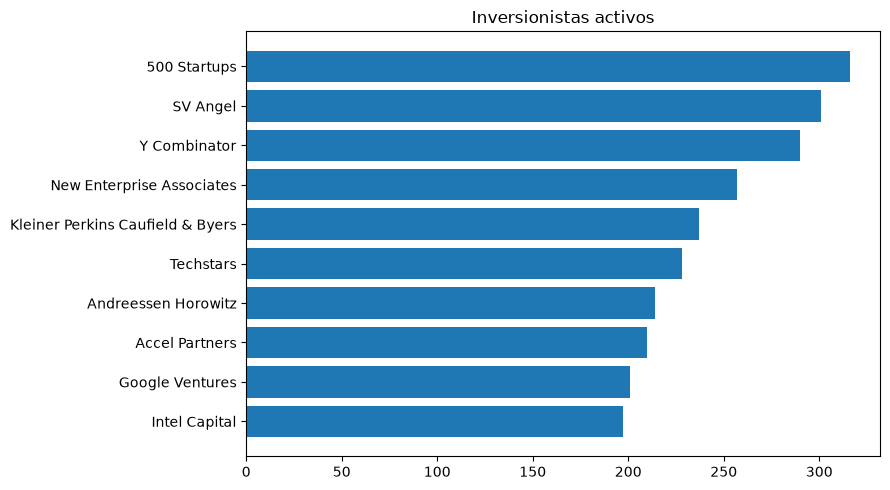

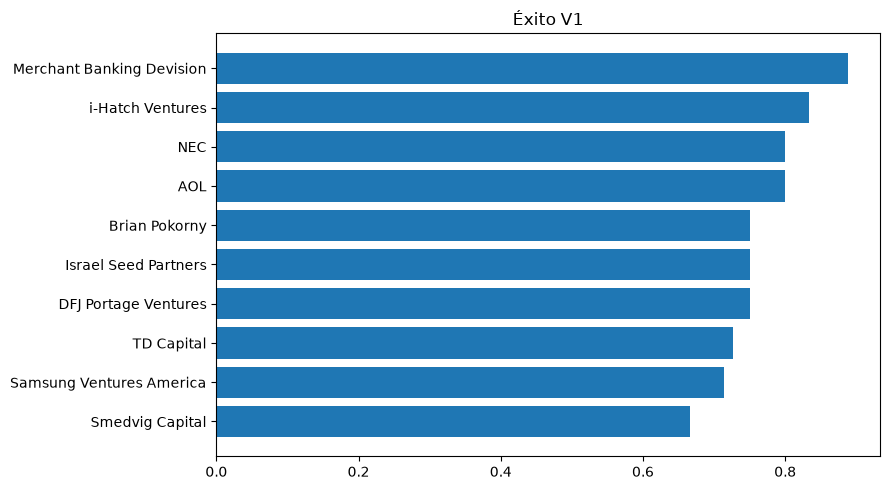

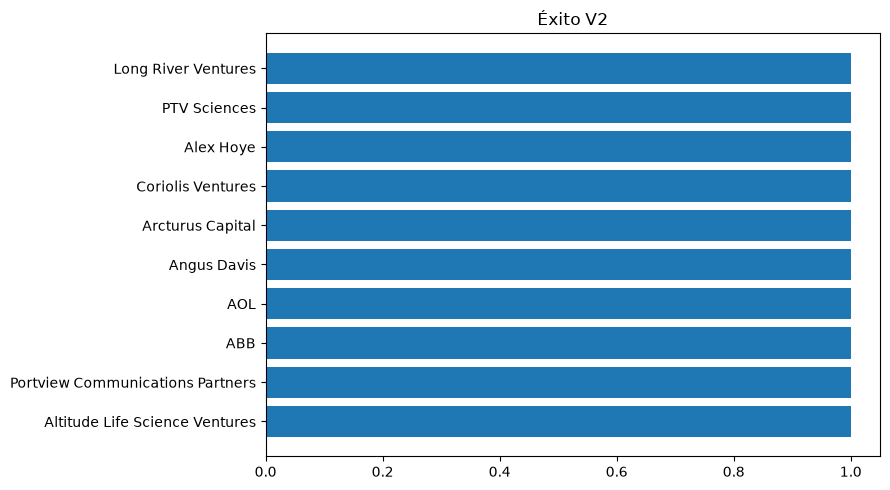

✓ Archivos exportados a C:\Users\Nany\proyectofinal\resultados_analista_inversiones
⚠ Éxito = proxy, no rentabilidad; observación limitada a 2013.


In [7]:
for df,campo,titulo in [(actividad.sort_values('rondas_activas',ascending=False).head(10),'rondas_activas','Inversionistas activos'),
                          (top1,'tasa_v1','Éxito V1'),(top2,'tasa_v2','Éxito V2')]:
    if df.empty: continue
    fig,ax=plt.subplots(figsize=(9,5))
    ax.barh(df.nombre.fillna(df.inversionista_id.astype(str)),df[campo])
    ax.invert_yaxis();ax.set_title(titulo);plt.tight_layout();plt.show()
SALIDA=Path.cwd()/'resultados_analista_inversiones'
SALIDA.mkdir(parents=True,exist_ok=True)
for nombre,df in [('actividad',actividad),('indicadores',indicadores),('benchmark',benchmark),('sensibilidad',sensibilidad)]:
    df.to_csv(SALIDA/f'{nombre}.csv',index=False)
print('✓ Archivos exportados a',SALIDA)
print('⚠ Éxito = proxy, no rentabilidad; observación limitada a 2013.')
